In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

from pprint import pprint

from functools import partial

import numpy as np
from sklearn.preprocessing import scale
# import sklearn.metrics as metrics
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
import matplotlib.animation as ani

import mlgrad.models as models
import mlgrad.regr as regr
import mlgrad.cls as cls
import mlgrad.pca as pca
import mlgrad.plots as plots
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss
import mlgrad.gd as gd
import mlgrad.smooth as smooth
import mlgrad.inventory as inventory
from mlgrad.af import averaging_function
import mlgrad.avragg as avragg

import rampy
import pybaselines
import random

from irsa import io
from irsa.preprocess import despike, utils
import irsa.widgets as widgets
import irsa.spectra as spectra
import irsa.io as io

import scipy.special as special

import copy

import ipywidgets
from IPython.display import display

import sys
print(sys.version)

# %matplotlib widget

3.13.12 (main, Feb  4 2026, 15:06:39) [GCC 15.2.0]


In [2]:
def plot_params(mod):
    ax = plt.twinx(plt.gca())
    # ax.plot((0,0), (mod.n_param,0), ls='--', lw=0.5, color='b')
    for mod in lfm1.models:
        param1 = np.asarray(mod.param[1:])
        # print(param1[0])
        param_p = param1.copy()
        param_m = param1.copy()
        param_p[param1 < 0] = 0
        param_m[param1 > 0] = 0
        ax.vlines(range(mod.n_input), 10*param_m, 10*param_p, color='k')
    ax.minorticks_on()


In [3]:
path = f"/home/intellimath/YD/repos/spectra/17"
options = {}
dd = {}
# widgets.load_spectra(path, dd, options)

In [4]:
# dd = io.load_spectra(path, {"вид_бактерий":"STR", "отсечки_по_молекулярной_массе":"less30more10"})
# dd = io.load_spectra(path, {"штамм_бактерий":["36", "95", "B", "C"], "тип_измерения_спектров":["SE"],
#                             "отсечки_по_молекулярной_массе": ["less100"],})
# dd = io.load_spectra(path, {"штамм_бактерий":["36", "95"], #"A", "B", "C", "D"], 
#                              "отсечки_по_молекулярной_массе": "less100",
#                              "тип_измерения_спектров":"SE"})
# dd = io.load_spectra(path, {})
dd = io.load_spectra(path, {"вид_бактерий":["SA", "SS", "SH"], 
                            "номер_цикла":["15"], 
                            "лизис":"термический",
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            # "отсечки_по_молекулярной_массе": ["more100"],
                            
                           }, verbose=False)

In [5]:
dd.align_bottom()
dd.crop(400)
dd.scale_by_mean()

In [6]:
dd.take(list(range(15)))

In [7]:
dd.flatten()

In [8]:
# dd.plot_sigma_mu(1.0, n_component=100)

In [9]:
dd.drop_zeros_spectrum()
dd.drop_notfinite()
dd.drop_empty()
dd.isfinite()

In [10]:
dd.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__15_5_1…

In [ ]:
dd.subtract_baselines(tau2=1.0e3, 
                      func=funcs.RStep(0.001, 0.001),
                      func2_e=inventory.relative_abs_max,
                     )

FloatProgress(value=0.0, bar_style='success', description='SA_97__15_5_1_1_термический_20260420_super_SE__H2O(…

In [ ]:
# dd2.scale_by_zscore()
dd.scale_by_mean()

In [ ]:
dd.plot_spectra()

In [ ]:
# dd.save("/home/intellimath/work/spectra/17_termo3", "rm_bl")

In [3]:
dd2 = spectra.SpectraCollection()
dd2.load("/home/intellimath/work/spectra/17_termo3", "rm_bl")

In [4]:
# dd2.plot_spectra(False)

In [5]:
dd_SA = dd2.subcollection_by_attr_value("вид_бактерий", "SA")
dd_SS = dd2.subcollection_by_attr_value("вид_бактерий", "SS")
dd_SH = dd2.subcollection_by_attr_value("вид_бактерий", "SH")

Ys_SA = dd_SA.union_y()
Ys_SS = dd_SS.union_y()
Ys_SH = dd_SH.union_y()
Ys = dd2.union_y()
print(len(Ys_SA), len(Ys_SS), len(Ys_SH))


868 884 879


In [7]:
# dd_SA.plot_spectra(False)

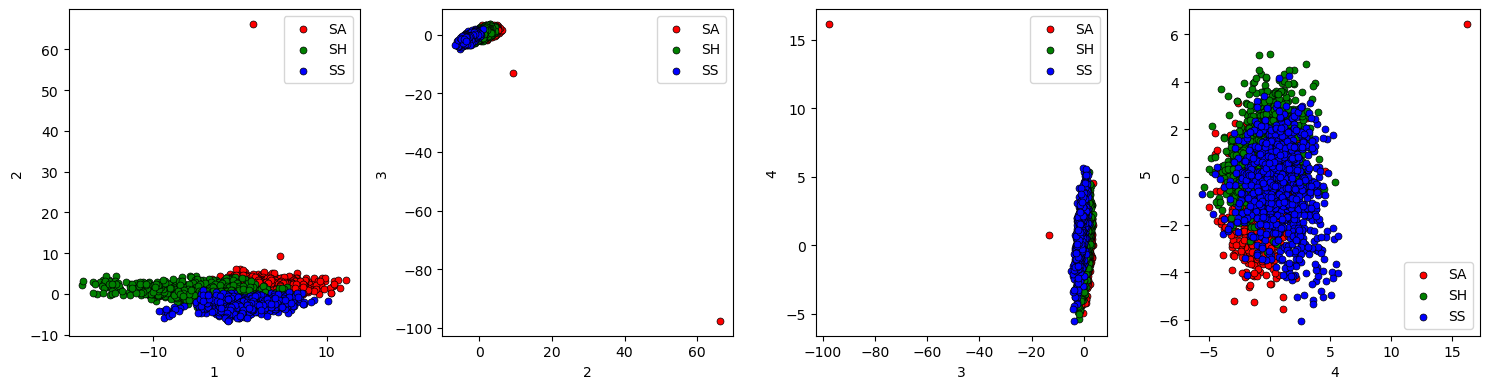

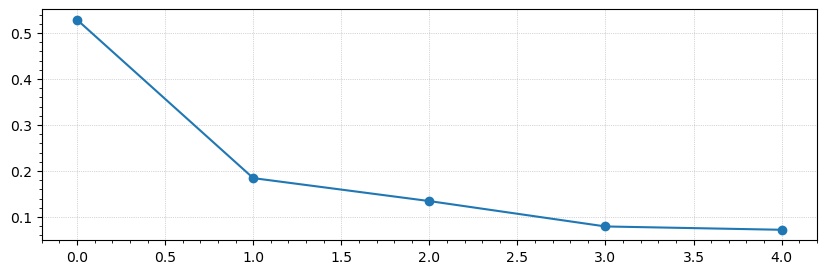

In [6]:
c, As, Ls = pca.find_loc_and_pc(Ys, 5)
U = (Ys - c) @ As.T
U_SA = (Ys_SA - c) @ As.T
U_SS = (Ys_SS - c) @ As.T
U_SH = (Ys_SH - c) @ As.T
plt.figure(figsize=(15,4))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.scatter(U_SA[:,i], U_SA[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SA")
    plt.scatter(U_SH[:,i], U_SH[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    plt.scatter(U_SS[:,i], U_SS[:,i+1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SS")
    plt.xlabel(str(i+1))
    plt.ylabel(str(i+2))
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
plt.tight_layout()
plt.legend()
plt.show()

plt.figure(figsize=(10,3))
plt.plot(Ls/Ls.sum(), marker='o')
plt.grid(ls=':', lw=0.5)
plt.minorticks_on()
plt.show()

In [9]:
# dd2.drop_zeros_spectrum()
# dd2.drop_notfinite()

In [10]:
# dd2.plot_spectra()

In [11]:
# dd2.plot_mu_sigma()

In [12]:
# d2.plot_spectra_smoothed(tau2=10)

In [7]:
import mlgrad.models as models
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss

import mlgrad.regr as regr
import mlgrad.af as af

Zs_SS = np.ones(Ys_SS.shape[0])
Zs_SH = np.ones(Ys_SH.shape[0])
Zs_SA = np.ones(Ys_SA.shape[0])

ys = np.concatenate((Ys_SS, Ys_SH, Ys_SA), axis=0)
zs = np.concatenate((Zs_SS, 2*Zs_SH, 3*Zs_SA), axis=0)

ys1 = np.concatenate((Ys_SS,Ys_SH), axis=0)
zs1 = np.concatenate((Zs_SS,-Zs_SH), axis=0)
ys1 = np.ascontiguousarray(ys1)
zs1 = np.ascontiguousarray(zs1)

ys2 = np.concatenate((Ys_SH,Ys_SA), axis=0)
zs2 = np.concatenate((Zs_SH,-Zs_SA), axis=0)
ys2 = np.ascontiguousarray(ys2)
zs2 = np.ascontiguousarray(zs2)

ys3 = np.concatenate((Ys_SA,Ys_SS), axis=0)
zs3 = np.concatenate((Zs_SA,-Zs_SS), axis=0)
ys3 = np.ascontiguousarray(ys3)
zs3 = np.ascontiguousarray(zs3)

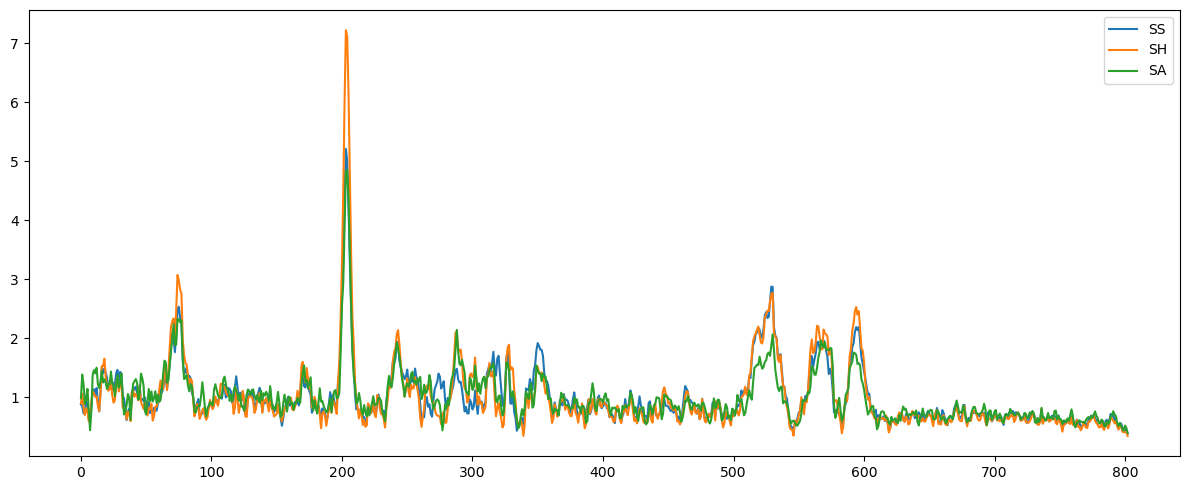

In [14]:
plt.figure(figsize=(12,5))
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.legend()
plt.tight_layout()
plt.show()

In [41]:
import joblib
import sys

def fit_snm(ys, zs, weights, tau=0, accuracy_min=0.75, n_try=5, sigma=10.0, p_threshold=1.0e-4):
    mod = models.SigmaNeuronModel(funcs.Sigmoidal(sigma), ys.shape[1])
    mod.allocate()
    mod.init_param()
    mod.use_regularizer(funcs2.AbsoluteNorm(), tau)

    if p_threshold != 0:
        projector = gd.Masked(mod, p_threshold)
    else:
        projector = None

    for i in range(n_try):
        mod.init_param()

        alg = regr.regression(ys, zs, mod,
                              loss_func=loss.ErrorLoss(funcs.SoftAbs_Sqrt(0.01)),
                              # loss_func=loss.ErrorLoss(funcs.Abs()),
                              # regnorm=funcs2.AbsoluteNorm(),
                              projector=projector, 
                              weights=weights,
                              h=0.002, n_iter=1000)
        w = accuracy_score(zs, np.sign(mod.evaluate(ys)))
        # sys.stdout.write(f"{w} {(mod.ob_param > 0).sum()}, ")
        # sys.stdout.flush()
        if w >= accuracy_min:
            break
    # sys.stdout.write("\n")
    return mod, w

def fit_lfm(ys, zs, tau=0, *, n_model=25, accuracy_min=0.75, n_try=5, sigma=10.0, p_threshold=1.0e-4):
    Np = (zs>0).sum()
    Nm = (zs<0).sum()
    N = Np + Nm
    
    weights = np.zeros(N)
    weights[zs > 0] = Nm / N
    weights[zs < 0] = Np / N

    with joblib.Parallel(n_jobs=2, max_nbytes=None, verbose=2) as parallel:
        results = parallel(
            joblib.delayed(fit_snm)(ys, zs, weights, tau=tau, accuracy_min=accuracy_min, n_try=n_try, sigma=sigma)
            for i in range(n_model)
        )

    lfm = models.LinearFuncModel()
    for mod, w in results:
    # for i in range(n_model):
    #     mod, w = fit_snm(ys, zs, weights, tau=tau, accuracy_min=accuracy_min, n_try=n_try, sigma=sigma, p_threshold=p_threshold)
        lfm.add(mod, w)

    inventory.normalize(lfm.weights.asarray())
    return lfm

#### SS/SH

In [42]:
lfm1 = fit_lfm(ys1, zs1, tau=500.0)
print(accuracy_score(zs1, np.sign(lfm1.evaluate(ys1))))

[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.


0.9773114010209869


[Parallel(n_jobs=2)]: Done  25 out of  25 | elapsed:    8.5s finished


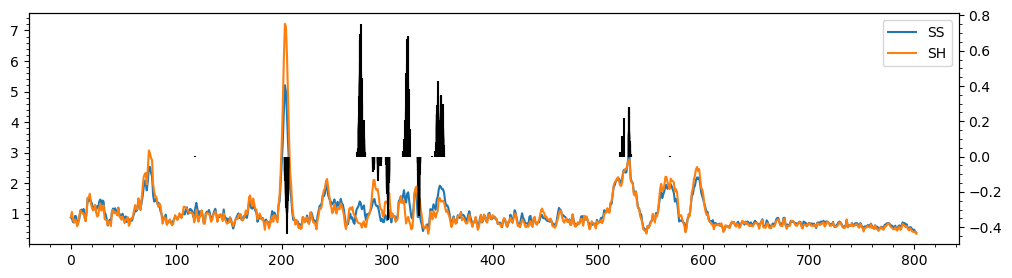

In [36]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.minorticks_on()
plt.legend()
plot_params(lfm1)
plt.show()
# print(np.asarray(lfm1.models[0].param))

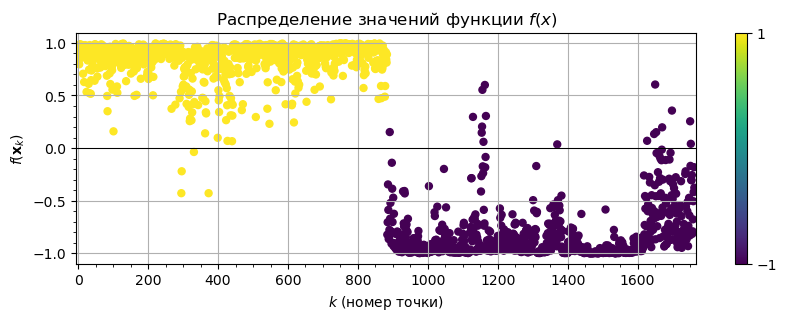

In [34]:
plt.figure(figsize=(10,3))
plots.plot_cls_function(lfm1, ys1, zs1)

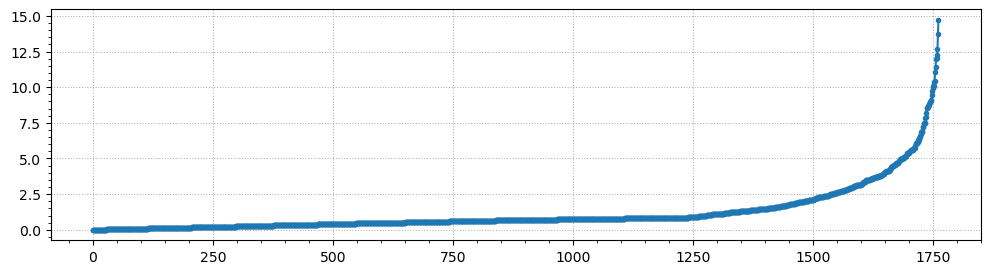

In [52]:
plt.figure(figsize=(12,3))
plt.plot(sorted(abs(inventory.modified_zscore(zs1*lfm1.evaluate(ys1)))), marker='o', ms=3)
plt.grid(ls=':', lw=0.75)
plt.minorticks_on()
plt.show()

In [33]:
# M1 = abs(inventory.modified_zscore(zs1*lfm1.evaluate(ys1)))
# I1 = (M1 < 3.5)
# ys1_wo = ys1[I1]
# zs1_wo = zs1[I1]

In [32]:
# lfm1 = fit_lfm(ys1_wo, zs1_wo, tau=150.0)
# print(lfm1.weights.asarray())
# inventory.normalize(lfm1.weights.asarray())
# print(accuracy_score(zs1, np.sign(lfm1.evaluate(ys1))))

In [33]:
# plt.figure(figsize=(12,3))
# plt.plot(Ys_SS.mean(axis=0), label="SS")
# plt.plot(Ys_SH.mean(axis=0), label="SH")
# plt.legend()
# plot_params(lfm1)
# plt.show()

In [34]:
# plt.figure(figsize=(10,3))
# plots.plot_cls_function(lfm1, ys1, zs1)

### SH SA

In [ ]:
lfm2 = fit_lfm(ys2, zs2, tau=500.0)
print(accuracy_score(zs2, np.sign(lfm2.evaluate(ys2))))

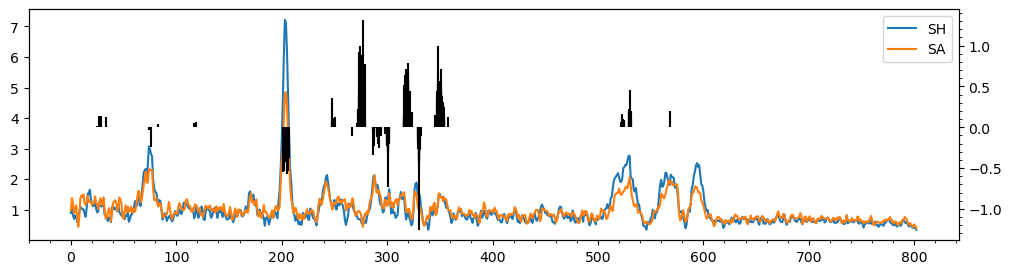

In [67]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.legend()
plot_params(lfm2)
plt.show()

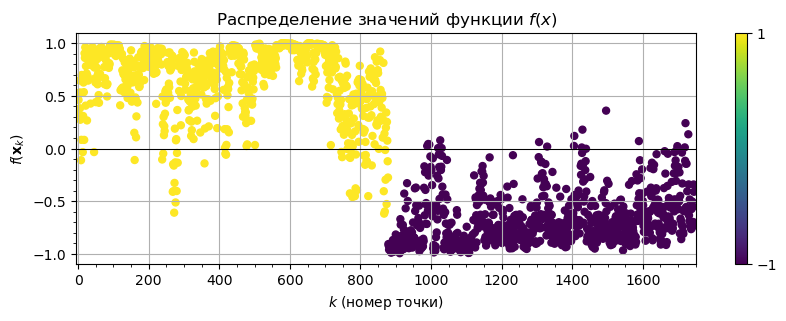

In [68]:
plt.figure(figsize=(10,3))
plots.plot_cls_function(lfm2, ys2, zs2)

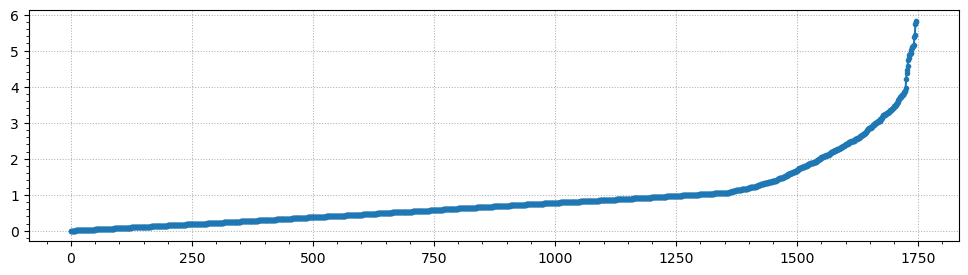

In [69]:
plt.figure(figsize=(12,3))
plt.plot(sorted(abs(inventory.modified_zscore(zs2*lfm2.evaluate(ys2)))), marker='o', ms=3)
# plt.plot(sorted(zs2*lfm2.evaluate(ys2)), marker='o', ms=3)
plt.grid(ls=':', lw=0.75)
plt.minorticks_on()
plt.show()

In [48]:
# M2 = abs(inventory.modified_zscore(zs2*lfm2.evaluate(ys2)))
# I2 = (M2 < 3.5)
# ys2_wo = ys2[I2]
# zs2_wo = zs2[I2]

In [41]:
# lfm2 = fit_lfm(ys2_wo, zs2_wo, tau=45.0)
# print(lfm2.weights.asarray())
# inventory.normalize(lfm2.weights.asarray())
# print(accuracy_score(zs2, np.sign(lfm2.evaluate(ys2))))

In [42]:
# plt.figure(figsize=(12,5))
# plt.plot(Ys_SH.mean(axis=0), label="SH")
# plt.plot(Ys_SA.mean(axis=0), label="SA")
# plt.legend()
# plot_params(lfm2)
# plt.show()

In [43]:
# plt.figure(figsize=(10,3))
# plots.plot_cls_function(lfm2, ys2, zs2)

### SA SS

In [70]:
lfm3 = fit_lfm(ys3, zs3, tau=400.0)
print(accuracy_score(zs3, np.sign(lfm3.evaluate(ys3))))

0.9942922374429224


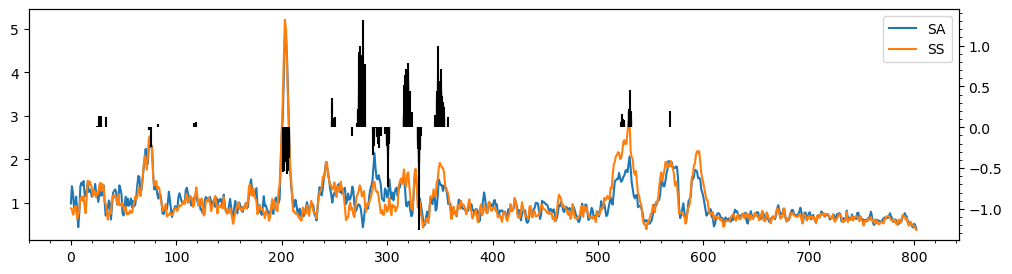

In [72]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.legend()
plot_params(lfm3)
plt.show()

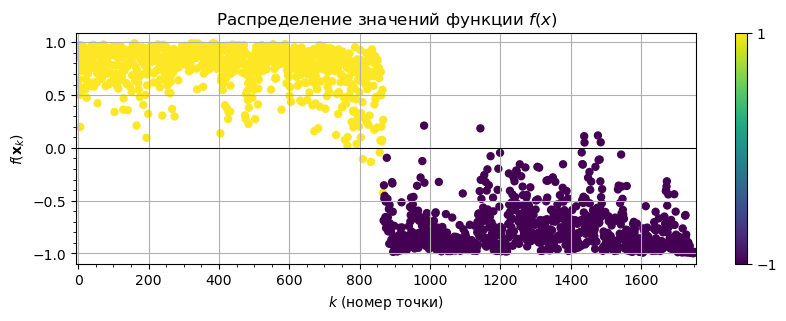

In [73]:
plt.figure(figsize=(10,3))
plots.plot_cls_function(lfm3, ys3, zs3)

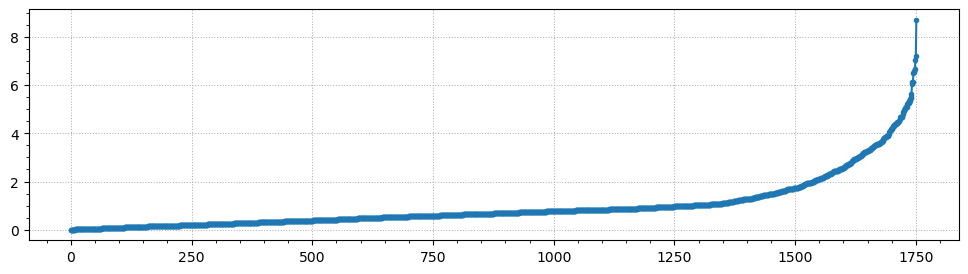

In [74]:
plt.figure(figsize=(12,3))
plt.plot(sorted(abs(inventory.modified_zscore(zs3*lfm3.evaluate(ys3)))), marker='o', ms=3)
plt.grid(ls=':', lw=0.75)
plt.minorticks_on()
plt.show()

In [55]:
# M3 = abs(inventory.modified_zscore(zs3*lfm3.evaluate(ys3)))
# I3 = (M3 < 3.5)
# ys3_wo = ys3[I3]
# zs3_wo = zs3[I3]

In [56]:
# lfm3 = fit_lfm(ys3_wo, zs3_wo, tau=150.0)
# print(lfm3.weights.asarray())
# inventory.normalize(lfm3.weights.asarray())
# print(accuracy_score(zs3, np.sign(lfm3.evaluate(ys3))))

In [57]:
# plt.figure(figsize=(12,5))
# plt.plot(Ys_SA.mean(axis=0), label="SA")
# plt.plot(Ys_SS.mean(axis=0), label="SS")
# plt.legend()
# plot_params(lfm3)
# plt.show()

In [58]:
# plt.figure(figsize=(10,3))
# plots.plot_cls_function(lfm3, ys3, zs3)

2631
899
836
996


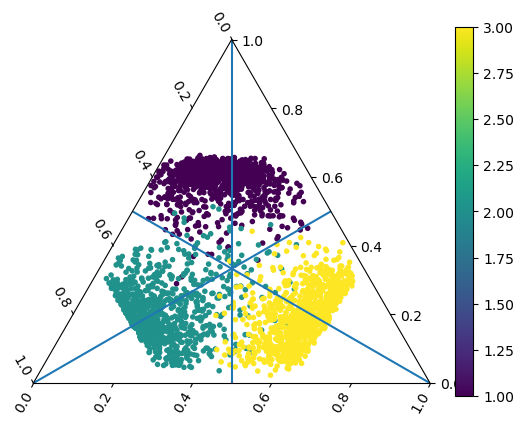

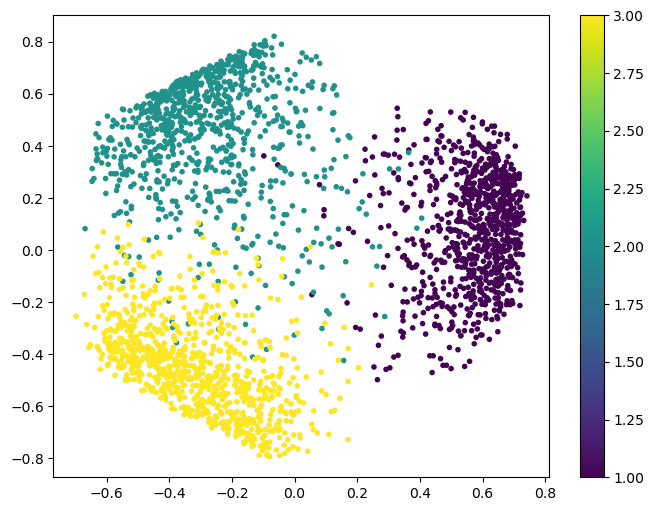

In [75]:
import mpltern
print(len(ys))

ax = plt.subplot(projection="ternary")
Z1 = lfm1.evaluate(ys)
Z2 = lfm2.evaluate(ys)
Z3 = lfm3.evaluate(ys)
Y1 = (1 + (Z1 - Z3) / 2) / 2
Y2 = (1 + (Z2 - Z1) / 2) / 2
Y3 = (1 + (Z3 - Z2) / 2) / 2
Y1[Y1<0] = 0
Y2[Y2<0] = 0
Y3[Y3<0] = 0
print(((Z1>0) & (Z3<0)).sum())
print(((Z2>0) & (Z1<0)).sum())
print(((Z2>0) & (Z3<0)).sum())
# print(Y1)
# print(Y2)
# print(Y3)
C = [(y1,y2,y3) for y1,y2,y3 in zip(Y1,Y2,Y3)]
# cax = ax.inset_axes([1.05, 0.1, 0.05, 0.9], transform=ax.transAxes)
cs = ax.scatter(Y1, Y2, Y3, c=zs, s=9)
plt.colorbar(cs)
ax.axline(
    [0.5, 0.0, 0.0],
    [0.5, 0.5, 0.5])
ax.axline(
    [0.0, 0.5, 0.0],
    [0.5, 0.5, 0.5])
ax.axline(
    [0.0, 0.0, 0.5],
    [0.5, 0.5, 0.5])
plt.show()

zz1 = Y1
zz2 = Y2 * np.exp(2j/3 * np.pi)
zz3 = Y3 * np.exp(-2j/3 * np.pi)
C = np.concatenate((Zs_SS, 2*Zs_SH, 3*Zs_SA))
plt.figure(figsize=(8,6))
cs = plt.scatter(np.real(zz1+zz2+zz3), np.imag(zz1+zz2+zz3), s=9, c=C)
plt.colorbar(cs)
plt.show()


## 

# *************************************************************

In [ ]:
import sympy
from sympy import MatrixSymbol, Identity, latex

In [ ]:
from IPython.display import display, Latex

In [ ]:
def latex_matrix(DD):
    n = DD.shape[0]
    s = r"$$\left(\begin{array}{" + n*"l" + "}"
    for i in range(10):
        for j in range(10):
            s += latex(DD[i,j])
            if j < n-1:
                s += r"&"
            else:
                s += r"\\"
    s += r"\end{array}\right)$$"
    # print(s)
    return s

In [ ]:
E = np.eye(10, dtype="i")
D2 = np.diff(E, 2, axis=0)
print(D2)
print(D2.T @ D2)

In [ ]:
w2 = sympy.symarray("w", (10,), )
W2 = np.diag(w2[0:-2])

In [ ]:
DD2 = np.dot(np.dot(D2.T, W2), D2)

In [ ]:
display(Latex(latex_matrix(DD2)))

In [ ]:
D1 = np.diff(np.eye(10, dtype="i"), 1, axis=0, )
print(D1)
print(D1.T @ D1)

In [ ]:
w = sympy.symarray("w", (10,))
W = np.diag(w[:-1])
DD1 = np.dot(np.dot(D1.T, W), D1)

In [ ]:
display(Latex(latex_matrix(DD1)))

In [ ]:
D3 = np.diff(np.eye(10, dtype="i"), 3, axis=0, )
print(D3)
print(D3.T @ D3)

In [ ]:
w3 = sympy.symarray("w", (10,), )
W3 = np.diag(w3[0:-3])

In [ ]:
DD3 = np.dot(np.dot(D3.T, W3), D3)

In [ ]:
display(Latex(latex_matrix(DD3)))

In [ ]:
D4 = np.diff(np.eye(10, dtype="i"), 4, axis=0, )
print(D4)
print(D4.T @ D4)

In [ ]:
w4 = sympy.symarray("w", (10,), )
W4 = np.diag(w4[0:-4])

In [ ]:
DD4 = np.dot(np.dot(D4.T, W4), D4)

In [ ]:
display(Latex(latex_matrix(DD4)))

In [ ]:
import ipywidgets as widgets
import os, time

In [ ]:
buttons = []
for i in range(10):
    buttons.append(widgets.Button(description=f"  The button {i}  "))
box = ipywidgets.Box(buttons)
box.layout = widgets.Layout(flex_flow="row wrap")
box

In [ ]:
fp = widgets.FloatProgress(min=0, max=10, value=0, bar_style="success", description="abcdefghijklmnopqrstuv")
fp.style.width=32
display(fp)
for i in range(11):
    time.sleep(1)
    fp.value=i